# Partie 5 — Extension générative : auto-encodeur variationnel (VAE)

**DiagnoCulture — un système hybride de diagnostic des maladies de la tomate**
Master « Apprentissage profond et hybride » · notebook `05_generative_extension`

Ce notebook traite la **Partie 5, Option B** de l'énoncé : entraîner un **VAE 64×64**, visualiser son espace latent, **générer** et **interpoler** des images, et comparer son erreur de reconstruction / **ELBO** à l'auto-encodeur de la Partie 3 comme **score d'anomalie**.

> **Ordre d'exécution.** Le notebook se lit et s'exécute **de haut en bas, en une seule passe** (`seed = 42`, résultats reproductibles). Les poids et figures sont sauvegardés sur Google Drive. Pour un run reproductible, exécuter la **section 2 (modèle neuf)** puis la **section 4 (entraînement) une seule fois** — relancer l'entraînement sans recréer le modèle fausse la reproductibilité.


## 0. Choix de l'option générative

**On choisit l'Option B (VAE)** plutôt que l'Option A (DCGAN). Raisons :

- **Réutilisation de l'infra P3** : mêmes images 64×64, pixels dans [0, 1], décodeur à sortie sigmoïde. On repart de l'auto-encodeur déjà maîtrisé.
- **Cohérence avec le fil du projet** : le VAE permet de comparer son erreur de reconstruction / ELBO à l'AE simple **comme score d'anomalie**, ce qui prolonge directement notre problème de rejet de l'inconnu (P4).
- **Risque maîtrisé** : un GAN serait plus instable (*mode collapse*, équilibre G/D) et nous ferait repartir de zéro — mauvais ratio résultat/risque sur un GPU gratuit et un délai court.

**Différence clé VAE vs auto-encodeur classique.** Un AE envoie chaque image sur **un point** de l'espace latent ; un VAE l'envoie sur **une petite zone** (une gaussienne de moyenne μ et de variance σ²). En forçant toutes ces zones à se tasser autour de l'origine, le VAE rend son espace latent **continu et sans trous** : on peut y échantillonner un point au hasard et le décoder en une image nouvelle et plausible. C'est ce qui permet la **génération**, l'**interpolation** et la **visualisation structurée** de l'espace latent.


## 1. Mise en place : graine, Drive, données, feuilles saines

On fixe la graine (reproductibilité), on monte Drive (sauvegardes), on récupère PlantVillage via kagglehub et on charge le `split.csv` figé en Partie 0.

**Point méthodologique important :** on entraîne le VAE **uniquement sur les feuilles saines**, exactement comme l'auto-encodeur de la Partie 3. C'est volontaire : pour que la comparaison des scores d'anomalie (section 9) soit **honnête**, le VAE et l'AE doivent avoir vu **la même distribution d'entraînement**. Un modèle qui aurait vu les maladies apprendrait qu'elles sont « normales » et ne pourrait plus les signaler. Conventions d'image identiques à la P3 : **64×64, pixels [0, 1], pas de normalisation** (la sortie est une sigmoïde).


In [11]:
# === 1 — Setup : seed, Drive, donnees, loaders saines ===
import os, random, numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# --- Reproductibilite (meme recette que les autres notebooks)
def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# --- Google Drive (pour sauver les poids et les figures)
from google.colab import drive
drive.mount('/content/drive')

ROOT    = "/content/drive/MyDrive/Project_clean"
DATA    = os.path.join(ROOT, "data")       # split.csv
MODELS  = os.path.join(ROOT, "models")     # .pt
RESULTS = os.path.join(ROOT, "results")    # figures .png + .csv
for d in (DATA, MODELS, RESULTS): os.makedirs(d, exist_ok=True)

# --- Donnees via kagglehub (cache ephemere, comme en P3/P4)
import kagglehub
dl_path = kagglehub.dataset_download("emmarex/plantdisease")
DATA_ROOT = os.path.join(dl_path, "PlantVillage")
print("DATA_ROOT:", DATA_ROOT)

# --- Split fige de la P0 (on ne recalcule rien)
split = pd.read_csv(os.path.join(DATA, "split.csv"))   # colonnes: path,label,class_idx,split

# --- Hyperparametres P5 (memes conventions image que la P3)
IMG_SIZE = 64
BATCH    = 128

tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),          # -> [0,1], PAS de Normalize (sortie VAE en sigmoide)
])

class LeafDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = Image.open(os.path.join(DATA_ROOT, r['path'])).convert('RGB')
        return tf(img), int(r['class_idx'])

# --- Entrainement sur feuilles SAINES uniquement (comme l'AE de la P3)
HEALTHY  = "Tomato_healthy"
train_df = split[(split.split == "train") & (split.label == HEALTHY)]
val_df   = split[(split.split == "val")   & (split.label == HEALTHY)]

vae_train = DataLoader(LeafDataset(train_df), batch_size=BATCH, shuffle=True,  num_workers=2)
vae_val   = DataLoader(LeafDataset(val_df),   batch_size=BATCH, shuffle=False, num_workers=2)
print("train saines:", len(train_df), "| val saines:", len(val_df))   # attendu ~1109 / 238

device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'plantdisease' dataset.
DATA_ROOT: /kaggle/input/plantdisease/PlantVillage
train saines: 1109 | val saines: 238


## 2. Le modèle : `ConvVAE`

L'architecture **reprend exactement l'encodeur et le décodeur de l'AE de la Partie 3** ; seules **deux choses changent** :

1. **Deux têtes au lieu d'une.** À partir des 4096 features de l'encodeur, deux couches linéaires produisent `fc_mu` (le **centre** μ de la gaussienne) et `fc_logvar` (le **log de la variance**). On prédit `logvar` plutôt que σ pour garantir σ = exp(0.5·logvar) > 0 sans contrainte, et pour la stabilité numérique.
2. **La reparamétrisation.** On ne peut pas rétropropager à travers un tirage aléatoire. On écrit donc `z = μ + σ·ε` avec `ε ∼ N(0, I)` : le hasard est déporté dans `ε` (une entrée, pas un paramètre), et le gradient passe proprement par μ et logvar. C'est l'astuce de Kingma & Welling (2013).

Le `forward` renvoie `x̂, μ, logvar` — on a besoin de μ et logvar pour le terme KL de la perte.


In [12]:
# === 2 — Modele : auto-encodeur variationnel convolutif (ConvVAE) ===
class ConvVAE(nn.Module):
    def __init__(self, k=64):
        super().__init__()
        self.k = k

        # ---------- ENCODEUR : 64x64 -> 8x8, 3 blocs Conv stride-2 (comme l'AE P3)
        self.enc = nn.Sequential(
            nn.Conv2d(3, 16, 4, stride=2, padding=1),  nn.BatchNorm2d(16), nn.ReLU(True),  # 64 -> 32
            nn.Conv2d(16, 32, 4, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(True),  # 32 -> 16
            nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(True),  # 16 -> 8
        )
        self.flat_dim = 64 * 8 * 8   # 4096

        # ---------- DEUX tetes : une distribution, pas un point
        self.fc_mu     = nn.Linear(self.flat_dim, k)   # moyenne       mu(x)
        self.fc_logvar = nn.Linear(self.flat_dim, k)   # log-variance  log(sigma^2)(x)

        # ---------- DECODEUR : k -> 8x8 -> 64x64, 3 ConvTranspose (comme l'AE P3)
        self.fc_dec = nn.Linear(k, self.flat_dim)
        self.dec = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.BatchNorm2d(32), nn.ReLU(True),  # 8  -> 16
            nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1), nn.BatchNorm2d(16), nn.ReLU(True),  # 16 -> 32
            nn.ConvTranspose2d(16, 3, 4, stride=2, padding=1),  nn.Sigmoid(),                       # 32 -> 64, pixels [0,1]
        )

    def encode(self, x):
        h = self.enc(x).flatten(1)                 # (B, 4096)
        return self.fc_mu(h), self.fc_logvar(h)    # mu, logvar

    def reparameterize(self, mu, logvar):
        # z = mu + sigma * eps,  sigma = exp(0.5*logvar),  eps ~ N(0, I)
        # le hasard est dans eps (une entree, pas un parametre) => le gradient passe par mu et logvar
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        h = self.fc_dec(z).view(-1, 64, 8, 8)
        return self.dec(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar                   # on renvoie mu/logvar pour la perte (KL)

# --- Instanciation (set_seed JUSTE avant : lecon repro de la P4) + verif des dimensions
set_seed(42)
vae = ConvVAE(k=64).to(device)
print(f"ConvVAE(k=64) — {sum(p.numel() for p in vae.parameters()):,} parametres")

xb, _ = next(iter(vae_train))
xb = xb.to(device)
xh, mu, logvar = vae(xb)
print("x:", tuple(xb.shape), "| x_hat:", tuple(xh.shape),
      "| mu:", tuple(mu.shape), "| logvar:", tuple(logvar.shape))

ConvVAE(k=64) — 874,595 parametres
x: (128, 3, 64, 64) | x_hat: (128, 3, 64, 64) | mu: (128, 64) | logvar: (128, 64)


**Lecture.** On obtient **874 595 paramètres**. L'AE de la P3 (k=64) en avait ~612 000 : l'écart de ~262 000 correspond **exactement à la deuxième tête** (`fc_logvar`, une couche 4096→64). Tout le surcoût du VAE sur l'AE se résume donc à « prédire une largeur en plus du centre ». Le batch traverse bien le réseau : `x̂` ressort en 64×64, et μ/logvar sont des vecteurs de dimension 64 par image.


## 3. La fonction de perte : l'ELBO

La perte du VAE est l'**ELBO** (*Evidence Lower BOund*), somme de deux termes :

- **Reconstruction** : la **même MSE que l'AE de la P3**. Elle tire vers une sortie fidèle. Seule, elle donnerait un AE ordinaire.
- **KL** : `KL = −0.5·Σ(1 + logvar − μ² − exp(logvar))`. Il mesure l'écart entre la gaussienne de chaque image et le prior N(0, I). En le minimisant, on **force toutes les gaussiennes à se tasser autour de 0 et à se chevaucher** → c'est lui qui bouche les trous de l'espace latent et rend la génération possible. C'est le même type de terme KL que l'auto-encodeur **parcimonieux** vu en cours, appliqué ici à la distribution latente.

**Le coefficient `β` est l'hyperparamètre sensible à surveiller** (l'équivalent, pour le VAE, du `noise_std` du débruiteur de la P3) :
- **β trop grand** → le KL écrase tout, le modèle met μ≈0 et σ≈1 partout et **ignore l'image** (*posterior collapse*) : les générations deviennent une seule feuille « moyenne » floue.
- **β trop petit** → bonnes reconstructions mais espace latent mal structuré → mauvaises générations au hasard.

On démarre à **β = 1.0**.


In [13]:
# === 3 — Perte ELBO = reconstruction + beta * KL ===
def vae_loss(x, x_hat, mu, logvar, beta=1.0):
    B = x.size(0)
    # 1) RECONSTRUCTION : MSE (comme l'AE P3), sommee sur les pixels, moyennee sur le batch
    recon = F.mse_loss(x_hat, x, reduction='sum') / B
    # 2) KL : rapproche chaque N(mu, sigma^2) du prior N(0, I)  -> structure l'espace latent
    #    KL = -0.5 * somme(1 + logvar - mu^2 - exp(logvar))
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / B
    # 3) ELBO a minimiser = reconstruction + beta * KL
    loss = recon + beta * kld
    return loss, recon, kld

# verif rapide sur le batch deja calcule en section 2
loss, recon, kld = vae_loss(xb, xh, mu, logvar, beta=1.0)
print(f"loss={loss.item():.1f} | recon={recon.item():.1f} | KL={kld.item():.1f}")

loss=421.5 | recon=414.2 | KL=7.3


**Lecture.** Au tout début (modèle non entraîné), la **reconstruction domine** (~414) et le **KL est faible** (~7) : les gaussiennes sont déjà proches de 0. Au fil de l'entraînement, la reconstruction va baisser et le KL monter un peu, puis se stabiliser.


## 4. Entraînement

Même recette que les autres parties : optimiseur **Adam (lr = 1e-3)**, **early-stopping** sur la perte de validation, sauvegarde du **meilleur** modèle sur Drive. On sépare reconstruction et KL dans l'historique pour tracer les courbes demandées par l'énoncé.

> **Note de reproductibilité (importante).** Pour un run propre, exécuter la **section 2** (qui recrée un modèle neuf avec `set_seed(42)`) **puis** cette section **une seule fois**. Relancer l'entraînement sans recréer le modèle poursuit l'entraînement précédent et casse la reproductibilité en une passe.


ep01 | train  352.0 (rec 328.1 / KL 23.9) | val  259.7 (rec 258.6 / KL  1.1)
ep02 | train  236.4 (rec 225.0 / KL 11.4) | val  222.4 (rec 218.3 / KL  4.0)
ep03 | train  183.9 (rec 172.6 / KL 11.3) | val  180.7 (rec 176.5 / KL  4.2)
ep04 | train  165.5 (rec 152.4 / KL 13.1) | val  158.2 (rec 150.1 / KL  8.1)
ep05 | train  156.2 (rec 141.7 / KL 14.5) | val  151.1 (rec 141.0 / KL 10.2)
ep06 | train  150.6 (rec 136.2 / KL 14.4) | val  145.5 (rec 132.4 / KL 13.1)
ep07 | train  146.1 (rec 130.9 / KL 15.2) | val  139.7 (rec 123.8 / KL 15.9)
ep08 | train  143.1 (rec 127.1 / KL 16.0) | val  139.0 (rec 120.2 / KL 18.8)
ep09 | train  140.8 (rec 124.1 / KL 16.7) | val  136.6 (rec 117.8 / KL 18.9)
ep10 | train  139.1 (rec 121.6 / KL 17.6) | val  135.6 (rec 118.1 / KL 17.5)
ep11 | train  137.2 (rec 119.7 / KL 17.4) | val  133.1 (rec 113.7 / KL 19.4)
ep12 | train  134.6 (rec 116.7 / KL 17.9) | val  130.7 (rec 112.0 / KL 18.7)
ep13 | train  132.9 (rec 114.4 / KL 18.5) | val  128.8 (rec 109.3 / KL 19.5)

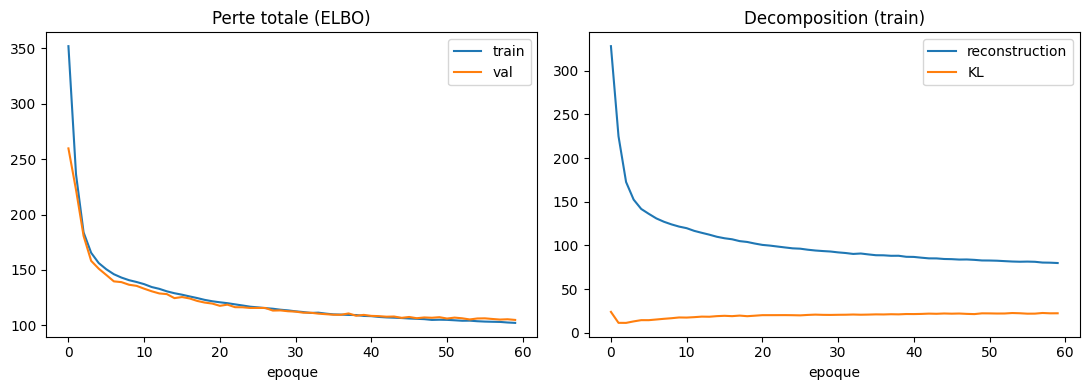

In [14]:
# === 4 — Entrainement du VAE (sur feuilles saines) ===
import time, json

BETA     = 1.0
EPOCHS   = 60
PATIENCE = 8
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)

def run_epoch(loader, train=True):
    vae.train() if train else vae.eval()
    tot, tot_rec, tot_kl, n = 0., 0., 0., 0
    torch.set_grad_enabled(train)
    for xb, _ in loader:
        xb = xb.to(device)
        x_hat, mu, logvar = vae(xb)
        loss, rec, kl = vae_loss(xb, x_hat, mu, logvar, beta=BETA)
        if train:
            opt.zero_grad(); loss.backward(); opt.step()
        b = xb.size(0)
        tot += loss.item()*b; tot_rec += rec.item()*b; tot_kl += kl.item()*b; n += b
    return tot/n, tot_rec/n, tot_kl/n

hist = {k: [] for k in ["tr_loss","tr_rec","tr_kl","va_loss","va_rec","va_kl"]}
best_val, bad = float("inf"), 0
t0 = time.time()

for ep in range(1, EPOCHS+1):
    tr = run_epoch(vae_train, train=True)
    va = run_epoch(vae_val,   train=False)
    for k, v in zip(["tr_loss","tr_rec","tr_kl"], tr): hist[k].append(v)
    for k, v in zip(["va_loss","va_rec","va_kl"], va): hist[k].append(v)
    print(f"ep{ep:02d} | train {tr[0]:6.1f} (rec {tr[1]:5.1f} / KL {tr[2]:4.1f})"
          f" | val {va[0]:6.1f} (rec {va[1]:5.1f} / KL {va[2]:4.1f})")

    # early-stopping + sauvegarde du meilleur sur Drive
    if va[0] < best_val - 1e-3:
        best_val, bad = va[0], 0
        torch.save(vae.state_dict(), os.path.join(MODELS, "vae_k64_best.pt"))
    else:
        bad += 1
        if bad >= PATIENCE:
            print(f"Early-stop a l'epoque {ep} (best val {best_val:.1f})"); break

print(f"Termine en {time.time()-t0:.0f}s | meilleure val loss = {best_val:.1f}")

# --- Courbes (perte totale + decomposition rec / KL)
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ax[0].plot(hist["tr_loss"], label="train"); ax[0].plot(hist["va_loss"], label="val")
ax[0].set_title("Perte totale (ELBO)"); ax[0].set_xlabel("epoque"); ax[0].legend()
ax[1].plot(hist["tr_rec"], label="reconstruction"); ax[1].plot(hist["tr_kl"], label="KL")
ax[1].set_title("Decomposition (train)"); ax[1].set_xlabel("epoque"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS, "vae_courbes.png"), dpi=120); plt.show()

**Lecture (run de référence, 60 époques, ~2 min sur T4).** Meilleure perte de validation **≈ 104,9**. Deux signaux sains :

- **Pas de *posterior collapse*** : le KL ne s'effondre pas vers 0, il se stabilise **autour de 22** → le modèle **utilise réellement** son espace latent pour encoder l'information.
- **Pas de sur-apprentissage** : les courbes train et validation se suivent de près jusqu'au bout.


## 5. Génération : échantillonner le prior et décoder

Le test qui prouve que l'espace latent est « rempli » : on tire des points `z` au hasard dans le prior **N(0, I)** et on les décode. Si des feuilles plausibles en sortent, la structure latente est bonne.


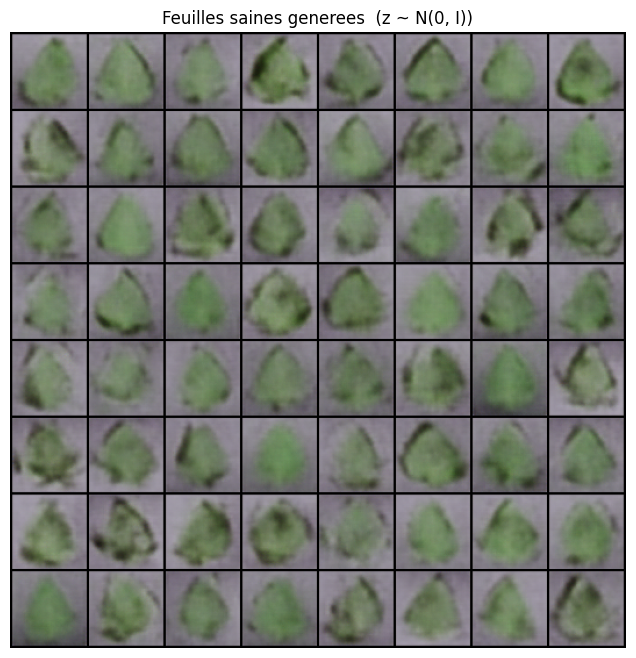

In [15]:
# === 5 — Generation : echantillonner le prior et decoder ===
import torchvision.utils as vutils

# on recharge le MEILLEUR modele sauve (pas celui de la derniere epoque)
vae.load_state_dict(torch.load(os.path.join(MODELS, "vae_k64_best.pt"), map_location=device))
vae.eval()

with torch.no_grad():
    z   = torch.randn(64, vae.k, device=device)   # 64 points tires au hasard dans N(0, I)
    gen = vae.decode(z).cpu()                      # -> 64 images [0,1], jamais vues dans le dataset

grid = vutils.make_grid(gen, nrow=8, padding=2)
plt.figure(figsize=(8,8)); plt.axis("off")
plt.title("Feuilles saines generees  (z ~ N(0, I))")
plt.imshow(grid.permute(1,2,0))
plt.savefig(os.path.join(RESULTS, "vae_generation.png"), dpi=120, bbox_inches="tight"); plt.show()

**Lecture.** On obtient des feuilles saines **reconnaissables mais un peu floues**. Ce flou est **attendu et assumé** : comme le rappelle le cours, la perte du VAE favorise une reconstruction « moyenne », d'où des images moins nettes qu'un GAN. L'essentiel n'est pas la netteté mais que **tout point tiré au hasard donne une feuille, jamais du bruit** → preuve que le KL a bien bouché les trous. La **diversité** des images (orientations, taches) confirme l'**absence de collapse**. On note aussi que le modèle **reproduit le fond de laboratoire uniforme** : il l'a encodé comme faisant partie de la « feuille » — illustration directe du **biais de fond** à discuter en Partie 6.


## 6. Interpolation latente entre deux feuilles

On marche **en ligne droite** dans l'espace latent entre les centres μ de deux vraies feuilles et on décode chaque point. On prend μ (et non un `z` tiré au hasard) pour une interpolation **nette et déterministe**.


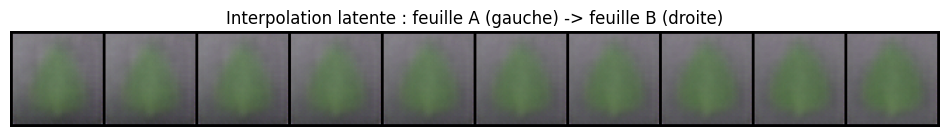

In [16]:
# === 6 — Interpolation entre deux feuilles dans l'espace latent ===
vae.eval()
xb, _ = next(iter(vae_val))
img1, img2 = xb[0:1].to(device), xb[1:2].to(device)   # 2 vraies feuilles saines (change les indices si tu veux)

with torch.no_grad():
    mu1, _ = vae.encode(img1)                 # on prend le CENTRE mu (pas un tirage) -> interpolation nette
    mu2, _ = vae.encode(img2)
    alphas = torch.linspace(0, 1, 10, device=device)
    zs = torch.cat([(1 - a) * mu1 + a * mu2 for a in alphas], dim=0)   # chemin droit mu1 -> mu2
    interp = vae.decode(zs).cpu()

grid = vutils.make_grid(interp, nrow=10, padding=2)
plt.figure(figsize=(12, 2.5)); plt.axis("off")
plt.title("Interpolation latente : feuille A (gauche) -> feuille B (droite)")
plt.imshow(grid.permute(1, 2, 0))
plt.savefig(os.path.join(RESULTS, "vae_interpolation.png"), dpi=120, bbox_inches="tight"); plt.show()

**Lecture.** La transition de la feuille A vers la feuille B est **progressive et douce**, et **chaque image intermédiaire reste une feuille plausible** : il n'y a que des feuilles entre deux feuilles, pas de « trou ». C'est la preuve visuelle de la **continuité** de l'espace latent — un auto-encodeur classique échouerait ici, car le milieu du chemin tomberait souvent sur du bruit. (Pour une figure plus parlante, choisir deux feuilles visuellement plus différentes, p. ex. `xb[0:1]` et `xb[7:8]`.)


## 7. Visualisation de l'espace latent (t-SNE), coloré par classe

On encode des images de **toutes les classes** (jeu de validation), on récupère le centre μ de chacune, et on projette ces vecteurs de dimension 64 en 2D par **t-SNE**.


classes tracees: 10


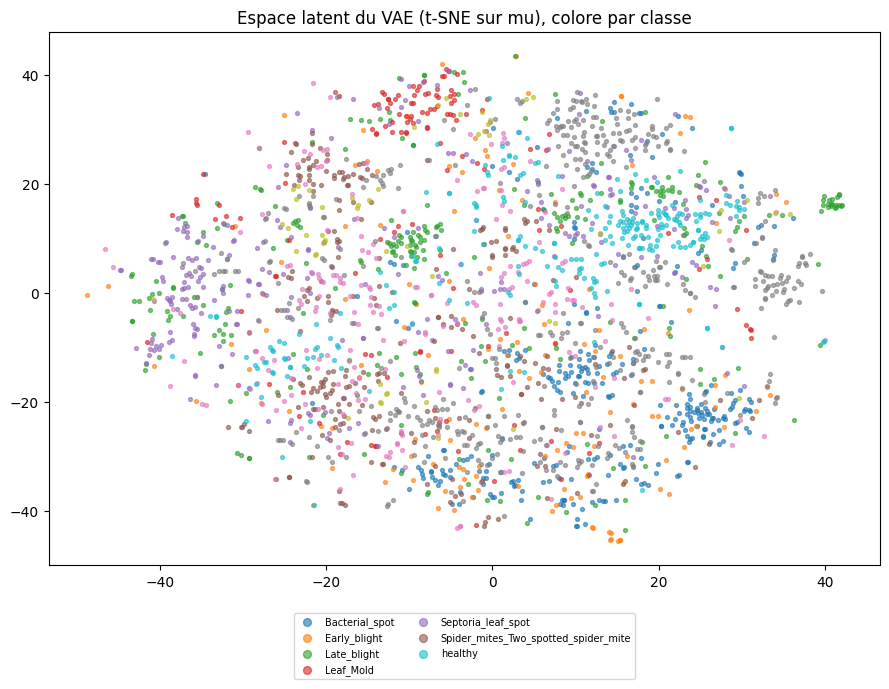

In [17]:
# === 7 — Espace latent 2D colore par classe (t-SNE sur mu) ===
from sklearn.manifold import TSNE

val_all = split[split.split == "val"]                              # toutes les classes
loader_all = DataLoader(LeafDataset(val_all), batch_size=256, shuffle=False, num_workers=2)

vae.eval()
mus, labels = [], []
with torch.no_grad():
    for xb, yb in loader_all:
        mu, _ = vae.encode(xb.to(device))     # on prend mu (le centre de la tache)
        mus.append(mu.cpu()); labels.append(yb)
mus    = torch.cat(mus).numpy()               # (N, 64)
labels = torch.cat(labels).numpy()
print("classes tracees:", len(set(labels)))  # doit afficher 10

emb = TSNE(n_components=2, random_state=42, init="pca", perplexity=30).fit_transform(mus)  # 64D -> 2D

id2name = split.drop_duplicates("class_idx").set_index("class_idx")["label"].to_dict()
plt.figure(figsize=(9,7))
for c in sorted(set(labels)):
    m = labels == c
    plt.scatter(emb[m,0], emb[m,1], s=8, alpha=0.6, label=id2name[c].replace("Tomato_",""))
plt.legend(markerscale=2, ncol=2, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.title("Espace latent du VAE (t-SNE sur mu), colore par classe")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS,"vae_latent_tsne.png"), dpi=120, bbox_inches="tight"); plt.show()

**Lecture.** Les classes ne forment **pas** de paquets nets par maladie — et c'est **un résultat, pas un défaut** : le VAE est **non supervisé** et entraîné **uniquement sur les saines**, il n'a donc aucune raison de ranger séparément des maladies qu'il n'a jamais apprises. La seule couleur qui forme une **concentration visible** est celle des **feuilles saines**, car ce sont les seules qu'il a appris à représenter. Conclusion : si, même dans l'espace latent, les maladies se noient parmi les saines, on s'attend à ce que le VAE soit un **détecteur d'anomalies faible** — ce que la section suivante vérifie chiffres en main.


## 8. Score d'anomalie du VAE

On évalue sur le **jeu de test mixte** (sain vs malade, label binaire). Pour chaque image on calcule deux scores et leur **AUROC** (capacité à séparer sain / anomalie) :

- l'**erreur de reconstruction** (MSE par image, même échelle que l'AE P3) ;
- l'**ELBO** = reconstruction + KL (score global).

On reconstruit de façon **déterministe** via `decode(mu)` (centre de la distribution, pas un tirage) pour un score reproductible et comparable à l'AE.


AUROC VAE (recon MSE) : 0.663
AUROC VAE (ELBO)      : 0.678


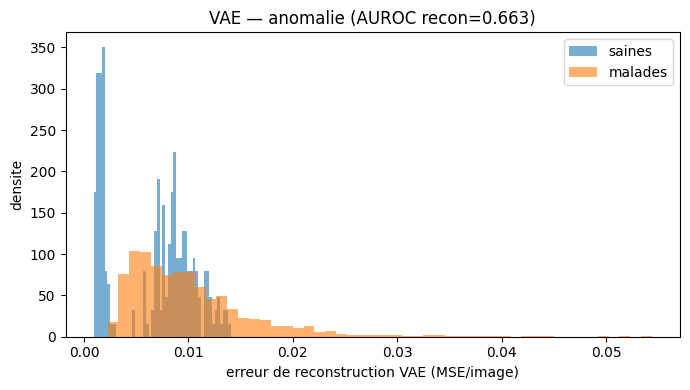

In [18]:
# === 8 — Score d'anomalie du VAE (test mixte sain/malade) ===
from sklearn.metrics import roc_auc_score

test_df = split[split.split == "test"].copy()
test_df["is_anom"] = (test_df["label"] != "Tomato_healthy").astype(int)   # 0=sain, 1=anomalie
test_loader = DataLoader(LeafDataset(test_df), batch_size=256, shuffle=False, num_workers=2)

vae.eval()
rec_scores, elbo_scores = [], []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        mu, logvar = vae.encode(xb)
        x_hat = vae.decode(mu)                          # reconstruction DETERMINISTE (centre mu, pas un tirage)
        rec  = ((x_hat - xb)**2).mean(dim=[1,2,3])      # MSE/image -> meme echelle que l'AE P3
        ksum = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp(), dim=1)  # KL/image
        elbo = ((x_hat - xb)**2).sum(dim=[1,2,3]) + ksum                        # recon(somme) + KL
        rec_scores.append(rec.cpu()); elbo_scores.append(elbo.cpu())

rec_scores  = torch.cat(rec_scores).numpy()
elbo_scores = torch.cat(elbo_scores).numpy()
y = test_df["is_anom"].values

print(f"AUROC VAE (recon MSE) : {roc_auc_score(y, rec_scores):.3f}")
print(f"AUROC VAE (ELBO)      : {roc_auc_score(y, elbo_scores):.3f}")

plt.figure(figsize=(7,4))
plt.hist(rec_scores[y==0], bins=50, alpha=0.6, density=True, label="saines")
plt.hist(rec_scores[y==1], bins=50, alpha=0.6, density=True, label="malades")
plt.xlabel("erreur de reconstruction VAE (MSE/image)"); plt.ylabel("densite")
plt.title(f"VAE — anomalie (AUROC recon={roc_auc_score(y, rec_scores):.3f})"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS,"vae_anomaly_hist.png"), dpi=120); plt.show()

**Lecture.** AUROC **0,663** (reconstruction) et **0,678** (ELBO). L'**ELBO est le meilleur** score : le terme KL apporte un signal supplémentaire, car une image malade (hors-distribution) tombe dans une zone **moins typique** de l'espace latent. Mais les histogrammes saines/malades **se chevauchent encore largement** — le détecteur reste faible.


## 9. Comparaison rigoureuse : AE (P3) vs VAE, sur le même test

Pour que la comparaison soit incontestable, on **recharge l'auto-encodeur débruiteur de la Partie 3** et on recalcule son AUROC sur **exactement le même** `test_loader`, avec la même reconstruction déterministe. Les trois chiffres sortent ainsi du même code. (On redéfinit ici la classe `ConvAutoencoder` de la P3, nécessaire pour charger ses poids.)


AE P3   (recon) : 0.615
VAE     (recon) : 0.663
VAE     (ELBO)  : 0.678


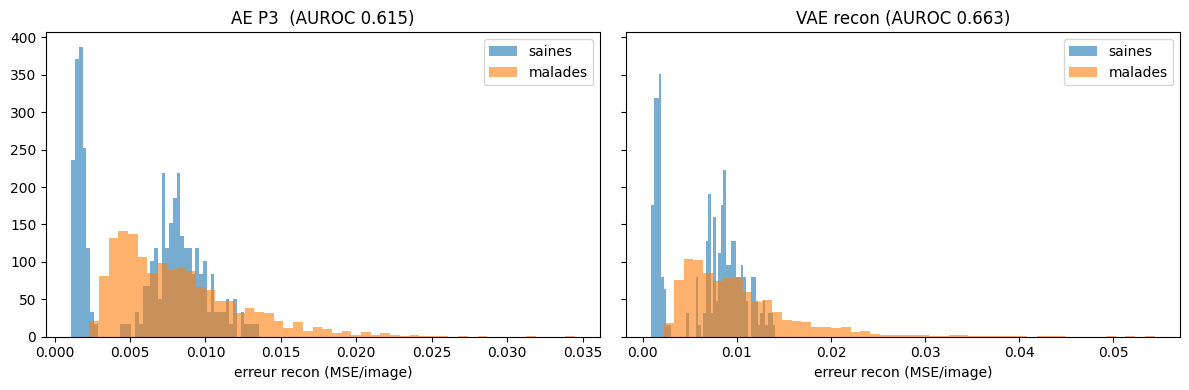

In [19]:
# === 9 — Comparaison AE (P3) vs VAE sur le MEME test ===

# --- classe de l'AE P3 (necessaire pour recharger les poids ae_k64_dn_best.pt)
class ConvAutoencoder(nn.Module):
    def __init__(self, k):
        super().__init__()
        self.encodeur = nn.Sequential(
            nn.Conv2d(3,  16, 4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 4, stride=2, padding=1), nn.ReLU(),
        )
        self.fc_enc = nn.Linear(64*8*8, k)
        self.fc_dec = nn.Linear(k, 64*8*8)
        self.decodeur = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 3,  4, stride=2, padding=1), nn.Sigmoid(),
        )
    def encode(self, x):
        return self.fc_enc(torch.flatten(self.encodeur(x), 1))
    def decode(self, z):
        return self.decodeur(self.fc_dec(z).view(-1, 64, 8, 8))
    def forward(self, x):
        return self.decode(self.encode(x))

# --- recharge l'AE debruiteur et calcule son AUROC sur le MEME test_loader
ae = ConvAutoencoder(k=64).to(device)
ae.load_state_dict(torch.load(os.path.join(MODELS, "ae_k64_dn_best.pt"), map_location=device))
ae.eval()

ae_scores = []
with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        x_hat = ae(xb)
        ae_scores.append(((x_hat - xb)**2).mean(dim=[1,2,3]).cpu())
ae_scores = torch.cat(ae_scores).numpy()

auroc_ae    = roc_auc_score(y, ae_scores)
auroc_vrec  = roc_auc_score(y, rec_scores)
auroc_velbo = roc_auc_score(y, elbo_scores)
print(f"AE P3   (recon) : {auroc_ae:.3f}")
print(f"VAE     (recon) : {auroc_vrec:.3f}")
print(f"VAE     (ELBO)  : {auroc_velbo:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12,4), sharey=True)
for a, s, name in [(ax[0], ae_scores,  f"AE P3  (AUROC {auroc_ae:.3f})"),
                   (ax[1], rec_scores, f"VAE recon (AUROC {auroc_vrec:.3f})")]:
    a.hist(s[y==0], bins=50, alpha=0.6, density=True, label="saines")
    a.hist(s[y==1], bins=50, alpha=0.6, density=True, label="malades")
    a.set_title(name); a.set_xlabel("erreur recon (MSE/image)"); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(RESULTS,"vae_vs_ae_anomaly.png"), dpi=120); plt.show()

**Lecture.** L'AE retombe **exactement à 0,615** (son chiffre de la P3) sur ce pipeline identique → la comparaison est **blindée** :

| méthode | AUROC |
|---|---|
| AE simple (P3) | 0,615 |
| VAE — reconstruction | 0,663 |
| **VAE — ELBO (recon + KL)** | **0,678** |

Le VAE fait **légèrement mieux** que l'AE, et l'ELBO est le meilleur score — mais tous restent **faibles** et les distributions se superposent. Le gain vient du terme KL, pas d'une capacité nouvelle à voir les lésions.


## 10. Récapitulatif des chiffres

In [20]:
# === 10 — Recap P5 ===
recap = pd.DataFrame([
    {"methode": "AE simple (P3)",       "AUROC": round(auroc_ae, 3)},
    {"methode": "VAE - reconstruction", "AUROC": round(auroc_vrec, 3)},
    {"methode": "VAE - ELBO",           "AUROC": round(auroc_velbo, 3)},
])
recap.to_csv(os.path.join(RESULTS, "p5_anomaly_results.csv"), index=False)
print(recap.to_string(index=False))

             methode  AUROC
      AE simple (P3)  0.615
VAE - reconstruction  0.663
          VAE - ELBO  0.678


## 11. Conclusion de la Partie 5

Le VAE entraîné sur feuilles saines produit un **espace latent continu** : on génère des feuilles saines plausibles par échantillonnage de N(0, I), et l'interpolation entre deux feuilles reste réaliste sur tout le chemin — deux propriétés qu'un auto-encodeur classique n'a pas. Les images générées sont volontairement un peu **floues**, comportement attendu d'un VAE (perte favorisant une reconstruction « moyenne »).

Côté **détection d'anomalies**, le VAE fait **légèrement mieux** que l'AE simple de la Partie 3 (AUROC **0,663** contre **0,615**), et son **ELBO** — qui ajoute le terme KL à la reconstruction — est le **meilleur score** (**0,678**) : une image malade tombe dans une zone moins typique de l'espace latent, ce que le KL capte en plus de l'erreur de reconstruction. Ce gain reste toutefois **modeste** et les distributions saines/malades se chevauchent largement : comme en Partie 3, un score fondé sur la **reconstruction moyennée sur l'image** rate les lésions **petites et locales**.

Le VAE apporte donc surtout une **capacité générative** et une amélioration **marginale** de la détection, sans résoudre le problème de fond. Cela éclaire directement la **question de synthèse n°4** de l'énoncé (limites de l'auto-encodeur comme détecteur d'anomalies : reconstruction « trop bonne », sensibilité au fond, cécité aux anomalies locales).

**Livrables de la partie (sur Drive) :** poids `vae_k64_best.pt` ; tableau `p5_anomaly_results.csv` ; figures `vae_courbes.png`, `vae_generation.png`, `vae_interpolation.png`, `vae_latent_tsne.png`, `vae_anomaly_hist.png`, `vae_vs_ae_anomaly.png`.
